# Week 2 class

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/goodman-imperial/discrete-maths-classes/blob/main/week-2-class.ipynb)

In this week's class we'll dive into the prime factoring algorithm and see how different algorithmic choices can affect performance.

We'll start by importing some standard libraries, don't worry about understanding this if you don't speak Python.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# Introduction

Now we'll do the stupidest possible algorithm to count the number of primes less than n. This algorithm is even stupider than the one from the videos. See if you can understand how it works and why it's even stupider.

In [9]:
op_count = 0

def stupidest_num_primes_less_than(n):
    global op_count
    op_count = 0
    def is_prime(n):
        global op_count
        if n==1:
            return False
        no_factors = True
        for j in range(2, n):
            op_count += 1
            if n%j==0:
                no_factors = False
        return no_factors
    count = 0
    for i in range(2, n+1):
        op_count += 1
        if is_prime(i):
            count += 1
    return count, op_count

>**Answer**
It is considered stupider due to no early return (refer to the program below)

In [10]:
def typical_is_prime(n):
    if n == 1:
        return False
    for j in range(2, n):   # note that the end point (n) is exclusive so compare till n-1
        if(n % j) == 0:
            return False    # early return
    return True

Now we're going to plot the number of primes less than n and the same thing on a log-log plot. Later, we'll do some more plotting, and you can just re-use this code with slight modifications.

We also fit a best fit line to the log-log plot. Why is this useful? It gives us a rough idea of how fast the algorithm is growing (although it's not perfect). How does that work? Well, suppose that $\log y = a \log x + b$ for some constants $a$ and $b$, then by taking exponentials of both sides we can see that $y=e^b x^a$, in other words $y=\Theta(x^a)$ in complexity notation. So the slope of the best fit line of a log-log plot gives you an approximate value for the polynomial power if the function grows like a polynomial.

WARNING! This will give you a value even if the growth is NOT polynomial. Indeed, the examples below are not polynomial, this is just to get a rough idea of how quickly they're growing.

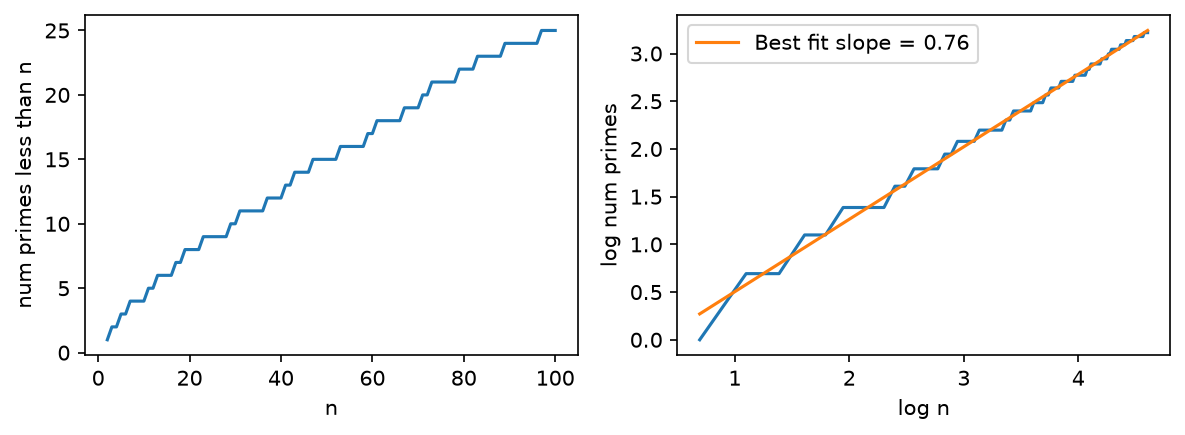

In [12]:
# x axis will be n, the integers from 2 to 1000
N = np.arange(2, 101)
# y axis will be the number of primes less than n
numprimes = np.array([stupidest_num_primes_less_than(n)[0] for n in N])

# Matplotlib code (feel free to reuse)
plt.figure(figsize=(8, 3), dpi=150)      # create a figure with width 8 and height 3
plt.subplot(121)                         # first subplot on the left
plt.plot(N, numprimes)                   # plot N on the x-axis and numprimes on the y-axis
plt.xlabel('n')                          # label axes
plt.ylabel('num primes less than n')
plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(numprimes))   # np.log uses function log from numpy package
# Now we fit a line (polynomial of degree 1) to the log-log data
# this returns [slope, intercept] of the best fit line
slope, intercept = np.polyfit(np.log(N), np.log(numprimes), 1)
plt.plot(np.log(N), slope*np.log(N)+intercept, label=f'Best fit slope = {slope:.2f}')
# then we label it
plt.xlabel('log n')
plt.ylabel('log num primes')
plt.legend(loc='best')
plt.tight_layout(); # and this makes everything use space nicely

# Class questions

## Q1: Count and plot the number of operations

The first task is to add code to the prime counting function to count the number of operations it does. Here's an example for a different function you can adapt.

In [5]:
operation_count = 0

def sum_of_n(n):
    global operation_count
    sum = 0
    operation_count += 1 # we set sum to 0
    for i in range(1, n+1):
        operation_count += 2 # we add 1 to i and compare to n+1
        sum += i
        operation_count += 1 # we add i to sum
    return sum

In this function you can see that the global variable ``operation_count`` starts at 0 and is increased repeatedly while the function is called. We've added 2 and then 1 in the loop body, but actually because constants don't matter for complexity notation, you can just add 1 in the loop body.

Right, now go ahead and adapt this idea to count the number of operations in ``stupidest_num_primes_less_than(n)``, and plot that and fit a best line to the log-log plot as above (just adapt that code).

Does it do what you'd expect from the lecture videos?

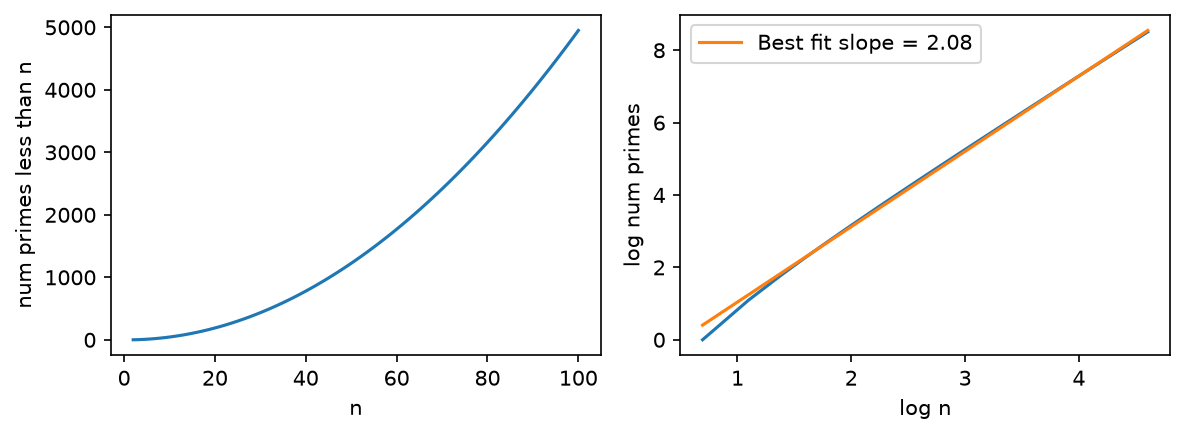

In [15]:
N = np.arange(2, 101)
plt.figure(figsize=(8, 3), dpi = 150)
plt.subplot(121)
operations = np.array([stupidest_num_primes_less_than(n)[1] for n in N])

plt.plot(N, operations)                   # plot N on the x-axis and numprimes on the y-axis
plt.xlabel('n')                          # label axes
plt.ylabel('num primes less than n')
plt.subplot(122)                         # second subplot on the right will be log-log
plt.plot(np.log(N), np.log(operations))   # np.log uses function log from numpy package
# Now we fit a line (polynomial of degree 1) to the log-log data
# this returns [slope, intercept] of the best fit line
slope, intercept = np.polyfit(np.log(N), np.log(operations), 1)
plt.plot(np.log(N), slope*np.log(N)+intercept, label=f'Best fit slope = {slope:.2f}')
# then we label it
plt.xlabel('log n')
plt.ylabel('log num primes')
plt.legend(loc='best')
plt.tight_layout(); # and this makes everything use space nicely

>Note: 
>In the graph on the right, the slope is around 2 which matches the power of n (takes at least $O({n^2})$)

## Version from lectures

Now modify your code to use the slightly less naive algorithm given in the lectures, where you break out of the inner loop once you find that a number is not prime. Analyse this. How does it compare?

In [32]:
def count_primes(n):
    op_count = 0
    num_of_primes = 0
    def is_prinme(n):
        if n == 1:
            return False
        for i in range(2, n):
            nonlocal op_count 
            op_count += 1
            if(n%i == 0):
                return False
        return True

    for j in range(n + 1):
        op_count += 1
        if(is_prinme(j)):
            num_of_primes += 1
    return num_of_primes, op_count


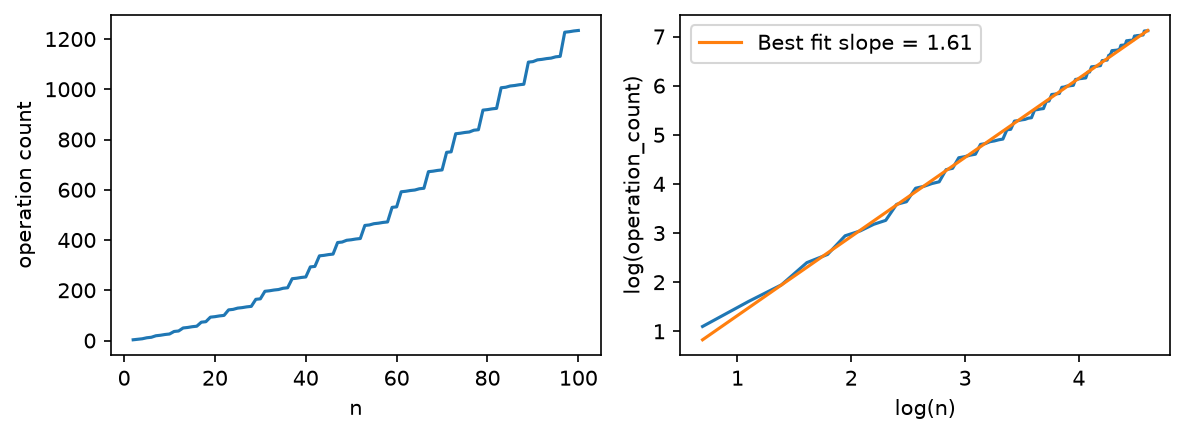

In [23]:
N = np.arange(2, 101)
plt.figure(figsize=(8, 3), dpi=150)
plt.subplot(121)
new_op_array = np.array([count_primes(n)[1] for n in N])
plt.plot(N, new_op_array)
plt.xlabel("n")
plt.ylabel("operation count")

plt.subplot(122)
plt.plot(np.log(N), np.log(new_op_array))
slope, intercept = np.polyfit(np.log(N), np.log(new_op_array), 1)
plt.plot(np.log(N), slope*np.log(N) + intercept, label=f'Best fit slope = {slope:.2f}')
plt.xlabel("log(n)")
plt.ylabel("log(operation_count)")
plt.legend(loc='best')
plt.tight_layout()

#### **Would having two functions with one calling the other work faster?**

In [30]:
op_count = 0
def is_prime(n):
    global op_count
    if n == 1:
        return False
    for i in range(2, n):
        op_count += 1
        if n%i == 0:
            return False
    return True

def count_num_of_primes(n):
    num_of_prime = 0
    global op_count
    op_count = 0
    for j in range(n+1):
        op_count += 1
        if(is_prime(j)):
            num_of_prime += 1
    return num_of_prime, op_count


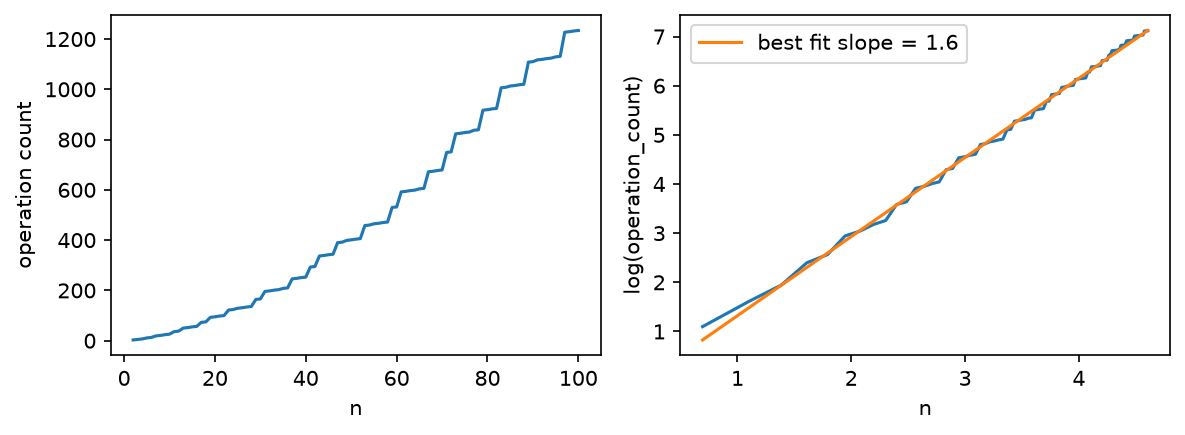

In [46]:
N = np.arange(2, 101)
plt.figure(figsize=(8, 3), dpi=150)
prime_op_count_3 = np.array([count_num_of_primes(n)[1] for n in N])
plt.subplot(121)
plt.plot(N, prime_op_count_3)
plt.xlabel("n")
plt.ylabel("operation count")

plt.subplot(122)
plt.plot(np.log(N), np.log(prime_op_count_3))
slope, intercept = np.polyfit(np.log(N), np.log(prime_op_count_3), 1)
plt.plot(np.log(N), slope*np.log(N) + intercept, label=f'best fit slope = {slope:.2}')
plt.xlabel("n")
plt.ylabel("log(operation_count)")
plt.legend(loc="best")
plt.tight_layout()

#### **Conclusion**

Whether the function is nested or separate would not affect the power of the polynomial, provided that they both loop over the exact same number of, well, numbers. This is because the op_count only increases for every iteration of loop which is a logic that will not change in both the nested and separate functions versions.

## Prime factor algorithm

Actually, to check if a number $n$ is prime, you don't need to just every possible factor below $n$, only up to $\sqrt{n}$. Why? Because if $m$ is a factor of $n$, then $n/m$ must also be a factor, and at least one of $m$ or $n/m$ must be smaller than $\sqrt{n}$. If both $m$ and $n/m$ were larger than $\sqrt{n}$ then the product of them both would be larger than $n$, but the product is just $n$.

Adapt your code to use this idea and compare its performance. This is known as the prime factor algorithm.

In [47]:
def count_primes2(n):
    op_count = 0
    num_of_primes = 0
    def is_prinme(n):
        if n == 1:
            return False
        for i in range(2, int(np.sqrt(n)) + 1):
            nonlocal op_count 
            op_count += 1
            if(n%i == 0):
                return False
        return True

    for j in range(n + 1):
        op_count += 1
        if(is_prinme(j)):
            num_of_primes += 1
    return num_of_primes, op_count


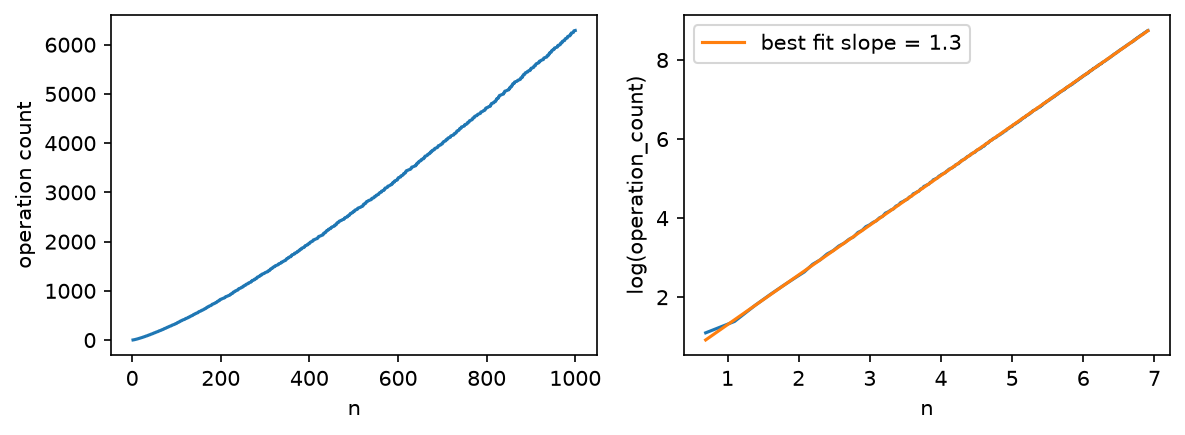

In [44]:
N = np.arange(2, 1001)
plt.figure(figsize=(8, 3), dpi=150)
prime_op_count_4 = np.array([count_primes2(n)[1] for n in N])
plt.subplot(121)
plt.plot(N, prime_op_count_4)
plt.xlabel("n")
plt.ylabel("operation count")

plt.subplot(122)
plt.plot(np.log(N), np.log(prime_op_count_4))
slope, intercept = np.polyfit(np.log(N), np.log(prime_op_count_4), 1)
plt.plot(np.log(N), slope*np.log(N) + intercept, label=f'best fit slope = {slope:.2}')
plt.xlabel("n")
plt.ylabel("log(operation_count)")
plt.legend(loc="best")
plt.tight_layout()

## Sieve of Eratosthenes

Finally, a much better algorithm is like the table method for the Fibonacci series. Rather than recomputing from scratch each time whether a number is prime, we re-use the calculations we've already made. In this case, start with a table of values saying all values from 2 to $n$ are prime. Loop through this from 2 to $n$, and if your value is prime, set all the multiples of it to be False. So in the first step you'd see that ``isprime[2]==True`` so you'd set ``isprime[4] = False``, ``isprime[6] = False`` and so on. Keep going until you've got to $\sqrt{n}$ and then count the number of values where ``isprime`` is True.

This algorithm is called the Sieve of Eratosthenes. Implement this algorithm and compare its performance.

In [41]:
def count_primes3(n):
    isprime = [True] * (n+1)
    isprime[0] = isprime[1] = False
    op_count =0
    
    for j in range(2, int(np.sqrt(n))+1):
        op_count += 1
        if not isprime[j]:
            continue
        for i in range(j*j, n + 1, j):
            op_count += 1
            isprime[i] = False
    
    return sum(isprime), op_count

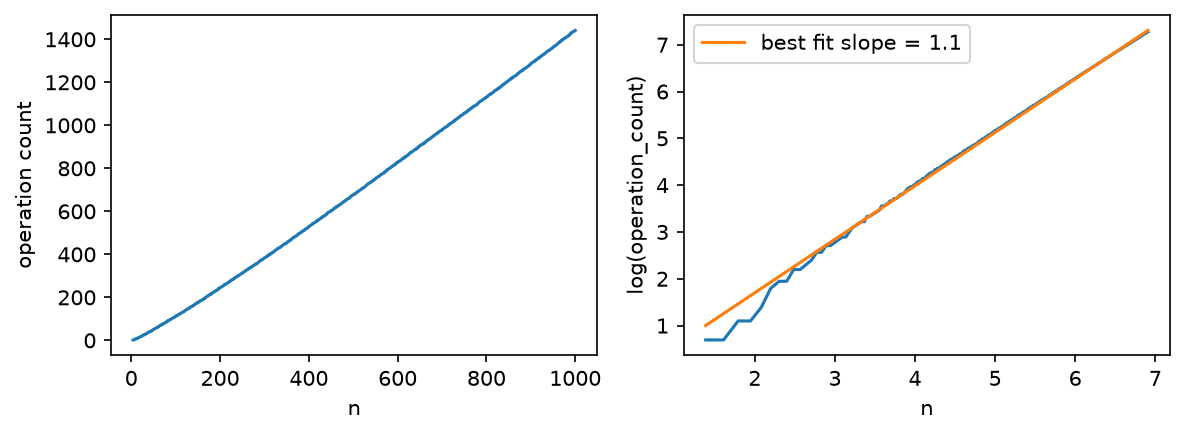

In [50]:
N = np.arange(4, 1001)
plt.figure(figsize=(8, 3), dpi=150)
prime_op_count_5 = np.array([count_primes3(n)[1] for n in N])
plt.subplot(121)
plt.plot(N, prime_op_count_5)
plt.xlabel("n")
plt.ylabel("operation count")

plt.subplot(122)
plt.plot(np.log(N), np.log(prime_op_count_5))
slope, intercept = np.polyfit(np.log(N), np.log(prime_op_count_5), 1)
plt.plot(np.log(N), slope*np.log(N) + intercept, label=f'best fit slope = {slope:.2}')
plt.xlabel("n")
plt.ylabel("log(operation_count)")
plt.legend(loc="best")
plt.tight_layout()

>Note: the slope of the sieve algorithm is same 1.3 at samples with n=100 then it drops to 1.1 when n=1000
>but the slope of the algorithm using sqrt() increases from 1.2 to 1.3 when sample upper limit increases from 100 to 1000

## Comparison

Finally, plot all the algorithms on the same axes to compare their performance.

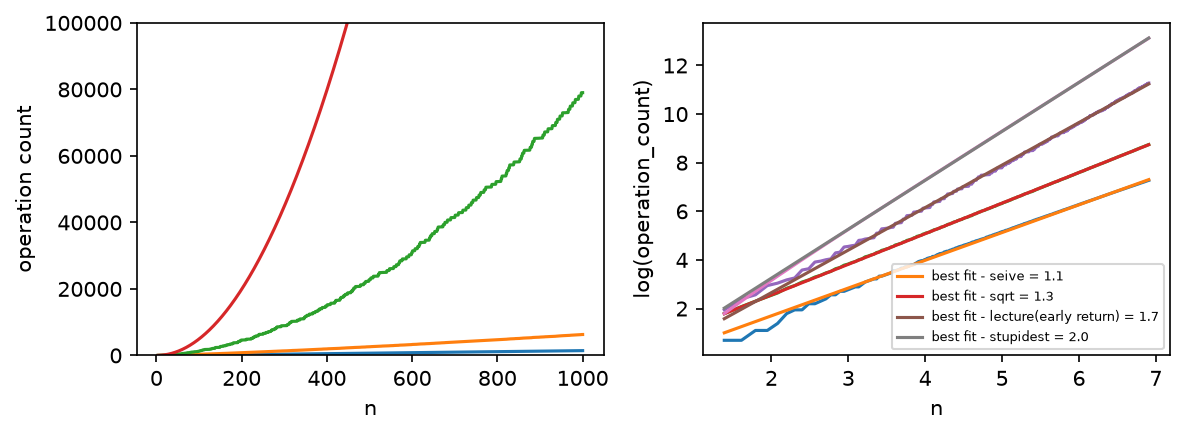

In [ ]:
N = np.arange(4, 1001)
prime_op_count_5 = np.array([count_primes3(n)[1] for n in N])
prime_op_count_4 = np.array([count_primes2(n)[1] for n in N])
prime_op_count_3 = np.array([count_num_of_primes(n)[1] for n in N])
operations = np.array([stupidest_num_primes_less_than(n)[1] for n in N])
plt.figure(figsize=(8, 3), dpi=150)
plt.subplot(121)
plt.ylim(0, 100000)             # zoom in on the faster algorithms
plt.plot(N, prime_op_count_5)
plt.plot(N, prime_op_count_4)
plt.plot(N, prime_op_count_3)
plt.plot(N, operations)
plt.xlabel("n")
plt.ylabel("operation count")

plt.subplot(122)
plt.plot(np.log(N), np.log(prime_op_count_5))
slope, intercept = np.polyfit(np.log(N), np.log(prime_op_count_5), 1)
plt.plot(np.log(N), slope*np.log(N) + intercept, label=f'best fit - seive = {slope:.2}')

plt.plot(np.log(N), np.log(prime_op_count_4))
slope2, intercept2 = np.polyfit(np.log(N), np.log(prime_op_count_4), 1)
plt.plot(np.log(N), slope2*np.log(N) + intercept2, label=f'best fit - sqrt = {slope2:.2}')

plt.plot(np.log(N), np.log(prime_op_count_3))
slope3, intercept3 = np.polyfit(np.log(N), np.log(prime_op_count_3), 1)
plt.plot(np.log(N), slope3*np.log(N) + intercept3, label=f'best fit - lecture(early return) = {slope3:.2}')

plt.plot(np.log(N), np.log(operations))
slope4, intercept4 = np.polyfit(np.log(N), np.log(operations), 1)
plt.plot(np.log(N), slope4*np.log(N) + intercept4, label=f'best fit - stupidest = {slope4:.2}')

plt.xlabel("n")
plt.ylabel("log(operation_count)")
plt.legend(loc="lower right", fontsize=6)       # loc is just a flag specifying the location of legend
plt.tight_layout()